### Imports

In [ ]:
import os
import pandas as pd
from tqdm.auto import tqdm
from itertools import product
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


### Dataset exploration

Scanning FIW: 100%|██████████| 980/980 [00:02<00:00, 442.18it/s]



            FAMILIES IN THE WILD (FIW) DATASET             

  GENERAL STRUCTURE
  ├─ Total families                         980
  ├─ Families with mid.csv                980
  ├─ Families w/o mid.csv                   0
  ├─ People (MID folders)               5,044
  └─ Total images                     26,540

  MEMBERS PER FAMILY          mean     med    min    max    std
                                5.1      5      2     41    2.5

  IMAGES PER FAMILY           mean     med    min    max    std
                               27.1     23      2    883   32.2

  IMAGES PER PERSON           mean     med    min    max    std
                                5.3      4      0    109    4.8

  GENDER (families with CSV)
  ├─ Male                                2,598
  ├─ Female                              2,666
  └─ Ratio M/F                            0.97

  IMAGE RESOLUTION (sample of 5,042 photos)
  ├─ Width       mean=132  med=108  min=108  max=224
  ├─ Height      mean=145  med=

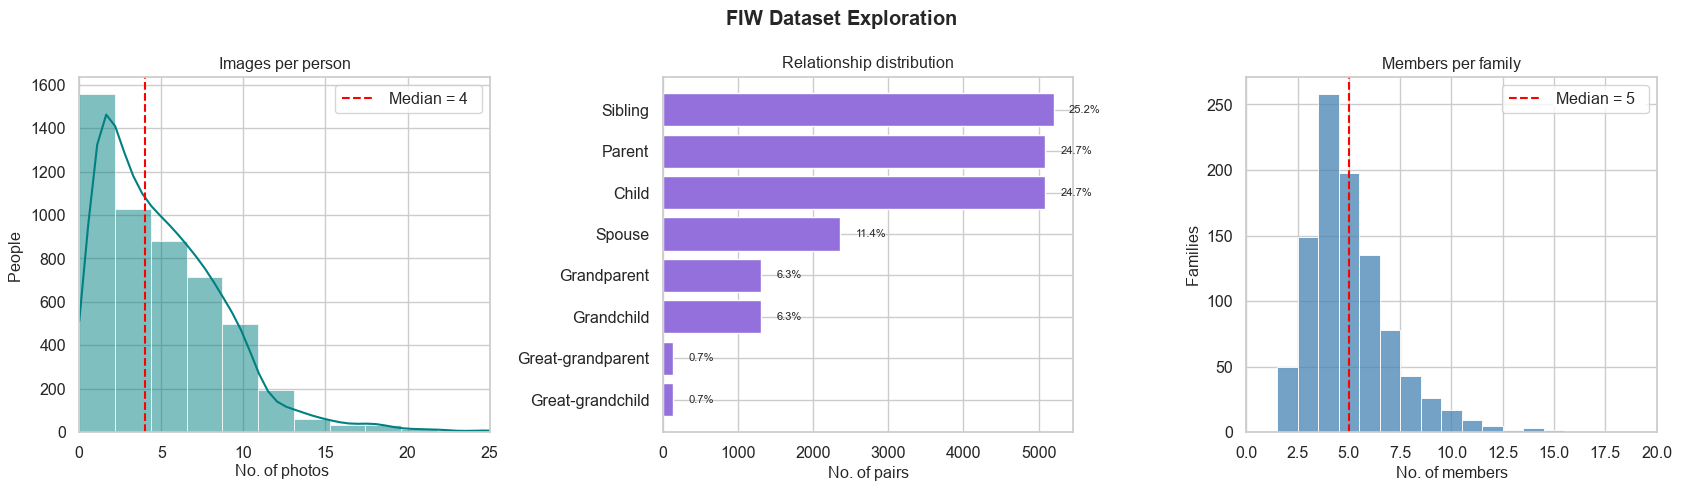

In [5]:
sns.set(style="whitegrid", font_scale=1.05)

RUTA_FIDS = r'..\data\raw\FIDs'
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# FIW relationship codes
REL_NOMBRES = {
    0: 'No relation', 1: 'Child', 2: 'Sibling',
    3: 'Grandchild', 4: 'Parent', 5: 'Spouse',
    6: 'Grandparent', 7: 'Great-grandchild',
    8: 'Great-grandparent', 9: 'TBD'
}

# =============================================
# 1. FULL DATASET SCAN
# =============================================
familias = sorted([d for d in os.listdir(RUTA_FIDS)
                   if os.path.isdir(os.path.join(RUTA_FIDS, d))])

registros = []        # per-member info
info_familias = []    # per-family info
relaciones_todas = [] # all relationships
imgs_dims = []        # image dimensions (sample)
fams_sin_csv = []

for fam in tqdm(familias, desc="Scanning FIW"):
    fam_path = os.path.join(RUTA_FIDS, fam)

    # ── Buscar miembros (carpetas MIDx) ──
    mids = sorted([d for d in os.listdir(fam_path)
                   if os.path.isdir(os.path.join(fam_path, d)) and d.startswith('MID')])

    imgs_familia = 0
    for mid in mids:
        mid_path = os.path.join(fam_path, mid)
        fotos = [f for f in os.listdir(mid_path)
                 if os.path.splitext(f)[1].lower() in IMG_EXTS]
        n_fotos = len(fotos)
        imgs_familia += n_fotos

        registros.append({
            'familia': fam, 'mid': mid, 'n_fotos': n_fotos
        })

        # Sample dimensions (1 image per person, not all)
        if fotos:
            try:
                img_path = os.path.join(mid_path, fotos[0])
                with Image.open(img_path) as im:
                    w, h = im.size
                    imgs_dims.append({'familia': fam, 'mid': mid,
                                      'width': w, 'height': h,
                                      'pixels': w * h})
            except Exception:
                pass

    # ── Read mid.csv for relationships and gender ──
    csv_path = None
    for nombre in ['mid.csv', f'{fam}.csv']:
        candidato = os.path.join(fam_path, nombre)
        if os.path.exists(candidato):
            csv_path = candidato
            break

    generos_fam = {'m': 0, 'f': 0, 'otro': 0}
    tiene_csv = csv_path is not None

    if tiene_csv:
        try:
            df_csv = pd.read_csv(csv_path)
            mid_col = df_csv.columns[0]

            # Find the gender column
            gender_col = None
            for c in df_csv.columns:
                if str(c).strip().lower() in ['gender', 'genero', 'sex']:
                    gender_col = c
                    break

            if gender_col:
                for _, row in df_csv.iterrows():
                    g = str(row[gender_col]).strip().lower()
                    if g in ['m', 'male']:
                        generos_fam['m'] += 1
                    elif g in ['f', 'female']:
                        generos_fam['f'] += 1
                    else:
                        generos_fam['otro'] += 1

            # Extraer relaciones
            skip_cols = {mid_col, gender_col}
            for c in df_csv.columns:
                if str(c).strip().lower() in ['name', 'nombre']:
                    skip_cols.add(c)

            rel_cols = []
            for c in df_csv.columns:
                if c in skip_cols:
                    continue
                try:
                    int(str(c))
                    rel_cols.append(c)
                except ValueError:
                    continue

            for _, row in df_csv.iterrows():
                for c in rel_cols:
                    try:
                        cod = int(row[c])
                        if cod > 0:
                            relaciones_todas.append(cod)
                    except (ValueError, TypeError):
                        pass
        except Exception:
            tiene_csv = False
    else:
        fams_sin_csv.append(fam)

    info_familias.append({
        'familia': fam, 'n_miembros': len(mids),
        'n_imagenes': imgs_familia, 'tiene_csv': tiene_csv,
        'n_male': generos_fam['m'], 'n_female': generos_fam['f']
    })

df_miembros  = pd.DataFrame(registros)
df_familias  = pd.DataFrame(info_familias)
df_dims      = pd.DataFrame(imgs_dims)

total_imgs = df_miembros['n_fotos'].sum()
total_personas = len(df_miembros)

# =============================================
# 2. REPORTE TEXTUAL
# =============================================
fams_con_csv = df_familias['tiene_csv'].sum()
m_total = df_familias['n_male'].sum()
f_total = df_familias['n_female'].sum()
rel_counts = Counter(relaciones_todas)

print(f"""
{'='*65}
{'FAMILIES IN THE WILD (FIW) DATASET':^65}
{'='*65}

  GENERAL STRUCTURE
  ├─ Total families                    {len(familias):>8}
  ├─ Families with mid.csv           {fams_con_csv:>8}
  ├─ Families w/o mid.csv            {len(fams_sin_csv):>8}
  ├─ People (MID folders)            {total_personas:>8,}
  └─ Total images                   {total_imgs:>8,}

  MEMBERS PER FAMILY          mean     med    min    max    std
                            {df_familias['n_miembros'].mean():>7.1f} {df_familias['n_miembros'].median():>6.0f} {df_familias['n_miembros'].min():>6} {df_familias['n_miembros'].max():>6} {df_familias['n_miembros'].std():>6.1f}

  IMAGES PER FAMILY           mean     med    min    max    std
                            {df_familias['n_imagenes'].mean():>7.1f} {df_familias['n_imagenes'].median():>6.0f} {df_familias['n_imagenes'].min():>6} {df_familias['n_imagenes'].max():>6} {df_familias['n_imagenes'].std():>6.1f}

  IMAGES PER PERSON           mean     med    min    max    std
                            {df_miembros['n_fotos'].mean():>7.1f} {df_miembros['n_fotos'].median():>6.0f} {df_miembros['n_fotos'].min():>6} {df_miembros['n_fotos'].max():>6} {df_miembros['n_fotos'].std():>6.1f}

  GENDER (families with CSV)
  ├─ Male                             {m_total:>8,}
  ├─ Female                           {f_total:>8,}
  └─ Ratio M/F                        {m_total/max(f_total,1):>8.2f}

  IMAGE RESOLUTION (sample of {len(df_dims):,} photos)
  ├─ Width       mean={df_dims['width'].mean():.0f}  med={df_dims['width'].median():.0f}  min={df_dims['width'].min()}  max={df_dims['width'].max()}
  ├─ Height      mean={df_dims['height'].mean():.0f}  med={df_dims['height'].median():.0f}  min={df_dims['height'].min()}  max={df_dims['height'].max()}
  └─ Megapixels mean={df_dims['pixels'].mean()/1e6:.2f}  med={df_dims['pixels'].median()/1e6:.2f}

  RELATIONSHIP DISTRIBUTION ({sum(rel_counts.values()):,} total pairs)""")
for cod in sorted(rel_counts.keys()):
    nombre = REL_NOMBRES.get(cod, f'Code {cod}')
    n = rel_counts[cod]
    pct = 100 * n / sum(rel_counts.values())
    print(f"    {cod} = {nombre:<20} {n:>8,}  ({pct:.1f}%)")

print(f"\n  PEOPLE WITHOUT PHOTOS: {(df_miembros['n_fotos']==0).sum()}")
print(f"{'='*65}")

# =============================================
# 3. PLOTS
# =============================================
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("FIW Dataset Exploration", fontsize=15, fontweight='bold')

# (a) Images per person → is there enough data per identity?
sns.histplot(df_miembros['n_fotos'], bins=50, kde=True, ax=ax[0], color='teal')
ax[0].axvline(df_miembros['n_fotos'].median(), color='red', ls='--',
              label=f"Mediana = {df_miembros['n_fotos'].median():.0f}")
ax[0].set(title='Images per person', xlabel='No. of photos', ylabel='People')
ax[0].set_xlim(0, 25)

ax[0].legend()

# (b) Relationship distribution → how imbalanced are the classes?
rels_sorted = sorted(rel_counts.items(), key=lambda x: x[1], reverse=True)
nombres = [REL_NOMBRES.get(k, f'Cod {k}') for k, _ in rels_sorted]
valores = [v for _, v in rels_sorted]
total_rel = sum(valores)
bars = ax[1].barh(nombres[::-1], valores[::-1], color='mediumpurple')
for bar, val in zip(bars, valores[::-1]):
    ax[1].text(bar.get_width() + total_rel * 0.01,
               bar.get_y() + bar.get_height() / 2,
               f'{100 * val / total_rel:.1f}%', va='center', fontsize=8)
ax[1].set_title('Relationship distribution')
ax[1].set_xlabel('No. of pairs')

# (c) Members per family → dataset structure
sns.histplot(df_familias['n_miembros'],
             bins=range(1, df_familias['n_miembros'].max() + 2),
             discrete=True, ax=ax[2], color='steelblue')
ax[2].axvline(df_familias['n_miembros'].median(), color='red', ls='--',
              label=f"Mediana = {df_familias['n_miembros'].median():.0f}")
ax[2].set(title='Members per family', xlabel='No. of members', ylabel='Families')
ax[2].legend()
ax[2].set_xlim(0, 20)


plt.tight_layout()
plt.show()

### Extract triads

In [ ]:
RUTA_FIDS = r'..\data\raw\FIDs'
OUT_CSV = os.path.join('..', 'data', 'processed', 'tripletes_fiw.csv') # Relationship codes (from FIW_RIDs.csv)
PARENT = 4
SPOUSE = 5

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}


# =============================================
# FUNCIONES
# =============================================
def listar_imagenes(carpeta):
    if not os.path.isdir(carpeta):
        return []
    return sorted([f for f in os.listdir(carpeta)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS])


def leer_mid_csv(csv_path):
    """
    Reads mid.csv and returns:
      rel  = {mid_i: {mid_j: relationship_code, ...}, ...}
      gender = {mid_i: 'm' or 'f', ...}
      mids = [1, 2, 3, ...]
    """
    try:
        df = pd.read_csv(csv_path)
    except Exception:
        return None, None, None

    if len(df) < 2:
        return None, None, None

    mid_col = df.columns[0]

    # Find the Name and Gender columns
    name_col, gender_col = None, None
    for c in df.columns:
        cl = str(c).strip().lower()
        if cl in ['name', 'nombre']:
            name_col = c
        if cl in ['gender', 'genero', 'sex']:
            gender_col = c

    if gender_col is None:
        return None, None, None

    # Relationship columns = the numeric ones (not MID, Name or Gender)
    rel_cols = []
    for c in df.columns:
        if c in [mid_col, name_col, gender_col]:
            continue
        try:
            int(str(c))
            rel_cols.append(c)
        except ValueError:
            continue

    # Construir diccionarios
    rel = {}
    gender = {}

    for _, row in df.iterrows():
        i = int(row[mid_col])
        gender[i] = str(row[gender_col]).strip().lower()
        rel[i] = {}
        for c in rel_cols:
            j = int(str(c))
            try:
                rel[i][j] = int(row[c])
            except (ValueError, TypeError):
                rel[i][j] = 0

    mids = list(rel.keys())
    return rel, gender, mids


# =============================================
# STEP 1: Extract triads from each family
# =============================================
print("Scanning families...")

familias = sorted([d for d in os.listdir(RUTA_FIDS)
                   if os.path.isdir(os.path.join(RUTA_FIDS, d))])

print(f"Families found: {len(familias)}")

todas_triadas = []
fam_con_triada = 0
fam_sin_csv = 0
fam_error = 0

for fam in tqdm(familias, desc="Reading relationships"):
    fam_path = os.path.join(RUTA_FIDS, fam)

    # Look for mid.csv or F####.csv
    csv_path = None
    for nombre in ['mid.csv', f'{fam}.csv']:
        candidato = os.path.join(fam_path, nombre)
        if os.path.exists(candidato):
            csv_path = candidato
            break

    if csv_path is None:
        fam_sin_csv += 1
        continue

    rel, gender, mids = leer_mid_csv(csv_path)
    if rel is None:
        fam_error += 1
        continue

    # Find couples (Spouse) and their children
    triadas_fam = []

    for i in mids:
        for j in mids:
            if i >= j:
                continue

            # Are they spouses?
            if rel.get(i, {}).get(j, 0) != SPOUSE:
                continue

            # Who is the father (m) and who is the mother (f)?
            gi = gender.get(i, '')
            gj = gender.get(j, '')

            if gi in ['m', 'male'] and gj in ['f', 'female']:
                padre, madre = i, j
            elif gj in ['m', 'male'] and gi in ['f', 'female']:
                padre, madre = j, i
            else:
                continue

            # Find children: BOTH parents have a PARENT relationship with k
            for k in mids:
                if k == padre or k == madre:
                    continue

                papa_es_parent = rel.get(padre, {}).get(k, 0) == PARENT
                mama_es_parent = rel.get(madre, {}).get(k, 0) == PARENT

                if papa_es_parent and mama_es_parent:
                    triadas_fam.append({
                        'familia': fam,
                        'padre_mid': f'MID{padre}',
                        'madre_mid': f'MID{madre}',
                        'hijo_mid': f'MID{k}'
                    })

    if triadas_fam:
        fam_con_triada += 1
        todas_triadas.extend(triadas_fam)

# =============================================
# STEP 2: Check photos and expand combinations
# =============================================

filas = []
triadas_validas = 0
triadas_sin_fotos = 0

for t in tqdm(todas_triadas, desc="Expanding"):
    fam = t['familia']

    imgs_p = listar_imagenes(os.path.join(RUTA_FIDS, fam, t['padre_mid']))
    imgs_m = listar_imagenes(os.path.join(RUTA_FIDS, fam, t['madre_mid']))
    imgs_h = listar_imagenes(os.path.join(RUTA_FIDS, fam, t['hijo_mid']))

    if not imgs_p or not imgs_m or not imgs_h:
        triadas_sin_fotos += 1
        continue

    triadas_validas += 1

    for ip, im, ih in product(imgs_p, imgs_m, imgs_h):
        filas.append({
            'p1_papa': f"{fam}/{t['padre_mid']}/{ip}",
            'p1_mama': f"{fam}/{t['madre_mid']}/{im}",
            'p2':      f"{fam}/{t['hijo_mid']}/{ih}"
        })

df_final = pd.DataFrame(filas)
df_final.to_csv(OUT_CSV, index=False)


# =============================================
# REPORTE FINAL
# =============================================

# Derivar info desde df_final
df_final['carpeta_papa'] = df_final['p1_papa'].str.rsplit('/', n=1).str[0]
df_final['carpeta_mama'] = df_final['p1_mama'].str.rsplit('/', n=1).str[0]
df_final['carpeta_hijo'] = df_final['p2'].str.rsplit('/', n=1).str[0]
df_final['familia'] = df_final['p2'].str.split('/').str[0]

V = df_final.groupby(['carpeta_papa', 'carpeta_mama', 'carpeta_hijo']).agg(
    n_p=('p1_papa', 'nunique'),
    n_m=('p1_mama', 'nunique'),
    n_h=('p2', 'nunique'),
    combinations=('p1_papa', 'size'),
    familia=('familia', 'first')
).reset_index()

imgs_unicas = set(df_final['p1_papa']) | set(df_final['p1_mama']) | set(df_final['p2'])
padres = set(V['carpeta_papa'])
madres = set(V['carpeta_mama'])
hijos  = set(V['carpeta_hijo'])
triadas_x_fam = V.groupby('familia').size()

print(f"""
{'='*60}
{'FIW DATASET — SUMMARY':^60}
{'='*60}
  Scanned families                 {len(familias):>8}
  Families with at least 1 triad  {fam_con_triada:>8}
  Final families (with photos)    {V['familia'].nunique():>8}
  No CSV / CSV with error         {fam_sin_csv:>5} / {fam_error}
{'─'*60}
  Detected triads                {len(todas_triadas):>8}
  Valid triads (with photos)     {triadas_validas:>8}
  Dropped triads                 {triadas_sin_fotos:>8}
{'─'*60}
  Total combinations              {len(df_final):>10,}
  Unique images                 {len(imgs_unicas):>10,}
{'─'*60}
  Unique fathers                  {len(padres):>8}
  Unique mothers                  {len(madres):>8}
  Unique children                 {len(hijos):>8}
  Unique people                   {len(padres|madres|hijos):>8}
{'='*60}

TRIADS/FAMILY           mean={triadas_x_fam.mean():.1f}  med={triadas_x_fam.median():.0f}  min={triadas_x_fam.min()}  max={triadas_x_fam.max()}
""")

Scanning families...
Families found: 980


Expanding: 100%|██████████| 2148/2148 [00:01<00:00, 1536.94it/s]



                   FIW DATASET — SUMMARY                    
  Scanned families                      980
  Families with at least 1 triad       820
  Final families (with photos)         788
  No CSV / CSV with error             0 / 0
────────────────────────────────────────────────────────────
  Detected triads                    2148
  Valid triads (with photos)         1979
  Dropped triads                      169
────────────────────────────────────────────────────────────
  Total combinations               2,299,212
  Unique images                     21,346
────────────────────────────────────────────────────────────
  Unique fathers                       951
  Unique mothers                       975
  Unique children                     1979
  Unique people                       3763

TRIADS/FAMILY           mean=2.5  med=2  min=1  max=21



## Initial environment setup

In [18]:
# =============================================
# CONFIGURATION
# =============================================

BASE_DIR = Path('..').resolve()

FACES_ROOT = BASE_DIR / 'data' / 'raw' / 'FIDs'
CSV_TRIPLETES = BASE_DIR / 'data' / 'processed' / 'tripletes_fiw.csv'
OUT_DIR = BASE_DIR / 'data' / 'splits'

SEED = 42
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

# Split ratios
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10

# Check paths
print(f"BASE_DIR:      {BASE_DIR}")
print(f"FACES_ROOT:    {FACES_ROOT}  → exists: {FACES_ROOT.exists()}")
print(f"CSV_TRIPLETES: {CSV_TRIPLETES}  → exists: {CSV_TRIPLETES.exists()}")
print(f"Split:         {TRAIN_RATIO}/{VAL_RATIO}/{TEST_RATIO}")

BASE_DIR:      <project-root>
FACES_ROOT:    <project-root>\data\raw\FIDs  → exists: True
CSV_TRIPLETES: <project-root>\data\processed\tripletes_fiw.csv  → exists: True
Split:         0.8/0.1/0.1


## Helper functions 

In [19]:
def norm_posix(s: str) -> str:
    return str(s).replace('\\', '/').replace('//', '/')

def carpeta_desde_ruta(p: str) -> str:
    p = norm_posix(p)
    return '/'.join(p.split('/')[:-1])

def familia_desde_ruta(p: str) -> str:
    return norm_posix(p).split('/')[0]

def reporte(nombre, df):
    cols_id = ['familia', 'carpeta_papa', 'carpeta_mama', 'carpeta_hijo']
    u = df.drop_duplicates(cols_id)
    imgs = set()
    imgs.update(df['p1_papa'].unique())
    imgs.update(df['p1_mama'].unique())
    imgs.update(df['p2'].unique())
    print(f"\n--- {nombre} ---")
    print(f"  Families:              {u['familia'].nunique()}")
    print(f"  Unique triads:         {len(u)}")
    print(f"  Combinaciones imgs:    {len(df):,}")
    print(f"  Unique images:         {len(imgs):,}")
    print(f"  People F/M/C:          "
          f"{u['carpeta_papa'].nunique()} / "
          f"{u['carpeta_mama'].nunique()} / "
          f"{u['carpeta_hijo'].nunique()}")

print("Functions loaded ✓")

Functions loaded ✓


### 80/10/10 split

In [20]:
print("Splitting by family...")

fam_train, fam_temp = train_test_split(
    familias, test_size=(VAL_RATIO + TEST_RATIO), random_state=SEED)
fam_val, fam_test = train_test_split(
    fam_temp, test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO), random_state=SEED)

fam_train, fam_val, fam_test = set(fam_train), set(fam_val), set(fam_test)

df_train = df[df['familia'].isin(fam_train)].copy()
df_val = df[df['familia'].isin(fam_val)].copy()
df_test = df[df['familia'].isin(fam_test)].copy()

print(f"  Train: {len(fam_train)} families  ({TRAIN_RATIO:.0%})")
print(f"  Val:   {len(fam_val)} families  ({VAL_RATIO:.0%})")
print(f"  Test:  {len(fam_test)} families  ({TEST_RATIO:.0%})")

Splitting by family...
  Train: 630 families  (80%)
  Val:   79 families  (10%)
  Test:  79 families  (10%)


In [24]:
(OUT_DIR / 'train_families.txt').write_text(
    '\n'.join(sorted(fam_train)) + '\n', encoding='utf-8')
(OUT_DIR / 'val_families.txt').write_text(
    '\n'.join(sorted(fam_val)) + '\n', encoding='utf-8')
(OUT_DIR / 'test_families.txt').write_text(
    '\n'.join(sorted(fam_test)) + '\n', encoding='utf-8')

df_train.to_csv(OUT_DIR / 'train_expanded.csv', index=False)
df_val.to_csv(OUT_DIR / 'val_expanded.csv', index=False)
df_test.to_csv(OUT_DIR / 'test_expanded.csv', index=False)

cols_id = ['familia', 'carpeta_papa', 'carpeta_mama', 'carpeta_hijo']
df_val_id = df_val.drop_duplicates(cols_id)
df_test_id = df_test.drop_duplicates(cols_id)
df_val_id.to_csv(OUT_DIR / 'val_identity.csv', index=False)
df_test_id.to_csv(OUT_DIR / 'test_identity.csv', index=False)

print('=' * 60)
print('REPORTE FINAL')
print('=' * 60)
reporte('TRAIN', df_train)
reporte('VAL', df_val)
reporte('TEST', df_test)


print('=' * 60)

REPORTE FINAL

--- TRAIN ---
  Families:              630
  Unique triads:         1571
  Combinaciones imgs:    2,167,992
  Unique images:         17,033
  People F/M/C:          758 / 780 / 1571

--- VAL ---
  Families:              79
  Unique triads:         196
  Combinaciones imgs:    46,689
  Unique images:         1,885
  People F/M/C:          96 / 97 / 196

--- TEST ---
  Families:              79
  Unique triads:         212
  Combinaciones imgs:    84,531
  Unique images:         2,428
  People F/M/C:          97 / 98 / 212


In [25]:
# =============================================
# EXTRA FILES TO SUPPORT THE 3 OPTIONS
# =============================================

# --- 1. Train by identity (Option A: averaging) ---
cols_id = ['familia', 'carpeta_papa', 'carpeta_mama', 'carpeta_hijo']
df_train_id = df_train.drop_duplicates(cols_id)
df_train_id.to_csv(OUT_DIR / 'train_identity.csv', index=False)

# --- 2. Sampled train (Option B: K combinations per triad) ---
K = 20
df_train_sampled = df_train.groupby(cols_id, sort=False).apply(
    lambda g: g.sample(n=min(K, len(g)), random_state=SEED)
).reset_index(drop=True)
df_train_sampled.to_csv(OUT_DIR / 'train_sampled_k20.csv', index=False)

# --- 3. Master list of ALL unique images (for embedding extraction) ---
imgs_todas = set()
for split_df in [df_train, df_val, df_test]:
    imgs_todas.update(split_df['p1_papa'].unique())
    imgs_todas.update(split_df['p1_mama'].unique())
    imgs_todas.update(split_df['p2'].unique())

imgs_todas = sorted(imgs_todas)

pd.DataFrame({'ruta_imagen': imgs_todas}).to_csv(
    OUT_DIR / 'all_unique_images.csv', index=False)

# --- REPORTE ---
print("=" * 60)
print("ARCHIVOS GENERADOS")
print("=" * 60)

print(f"\n--- OPTION A: Average embeddings per person ---")
print(f"  train_identity.csv:     {len(df_train_id):,} triads")
print(f"  val_identity.csv:       {len(df_val_id):,} triads")
print(f"  test_identity.csv:      {len(df_test_id):,} triads")

print(f"\n--- OPTION B: K={K} combinations per triad ---")
print(f"  train_sampled_k20.csv:  {len(df_train_sampled):,} rows")

print(f"\n--- OPTION C: All combinations ---")
print(f"  train_expanded.csv:     {len(df_train):,} rows")

print(f"\n--- FOR EMBEDDING EXTRACTION ---")
print(f"  all_unique_images.csv: {len(imgs_todas):,} images")

print(f"\n  This is what ArcFace will process.")
print(f"  It is done ONCE and serves all 3 options.")
print("=" * 60)

C:\Users\amita\AppData\Local\Temp\ipykernel_50484\206540035.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_train_sampled = df_train.groupby(cols_id, sort=False).apply(


ARCHIVOS GENERADOS

--- OPTION A: Average embeddings per person ---
  train_identity.csv:     1,571 triads
  val_identity.csv:       196 triads
  test_identity.csv:      212 triads

--- OPTION B: K=20 combinations per triad ---
  train_sampled_k20.csv:  28,666 rows

--- OPTION C: All combinations ---
  train_expanded.csv:     2,167,992 rows

--- FOR EMBEDDING EXTRACTION ---
  all_unique_images.csv: 21,346 images

  This is what ArcFace will process.
  It is done ONCE and serves all 3 options.
